problema: es posible saber si mi conjunto de datos permite predecir la clase "benigno o maligno" que los modelos no han visto existe algun patron que lo prediga sengun los valores en las columnas ? 
motivacion: mi evaluacion mostrara cuantas muestras clasifica correctamente cada modelo y en particulas cuantas muestreas malignas clasifica por error como benigna 
pregunta de investigacion: quiero saber cual de los modelos, regresion logistica o random fores logra mayor accuracy y si esa ventaja se mantiene en las tres particiones.

In [71]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import warnings 
warnings.filterwarnings('ignore')

In [72]:
df = pd.read_csv("breast-cancer-wisconsin.data",header=None) #tuve que ocupar None porque mi data no contiene el encabezado 

In [73]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       699 non-null    int64 
 1   1       699 non-null    int64 
 2   2       699 non-null    int64 
 3   3       699 non-null    int64 
 4   4       699 non-null    int64 
 5   5       699 non-null    int64 
 6   6       699 non-null    object
 7   7       699 non-null    int64 
 8   8       699 non-null    int64 
 9   9       699 non-null    int64 
 10  10      699 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 60.2+ KB


In [75]:
df.shape

(699, 11)

In [76]:
df=df.rename(columns={0:"Sample code number",1:"Clump Thickness",2:"Uniformity of Cell Size",3:"Uniformity of Cell Shape",4:"Marginal Adhesion",5:"Single Epithelial Cell Size",6:"Bare Nuclei",7:"Bland Chromatin",8:"Normal Nucleoli",9:"Mitoses",10:"Class"})

In [77]:
df.head()

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


tuve que ejecutar rename ya que mi data venia sin encabezado, tuve que agregar los titulos desde datadiccionary. esto me ayudo a reconocer que cada columna muestra informacion relacionada a los tamañosn, formas y caracteristicas de las celulas. las cuales pueden ser benignas o malignas como muestra mi columna CLass (Target)   

In [78]:
df.isnull().sum()

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

In [79]:
df["Sample code number"].unique()

array([ 1000025,  1002945,  1015425,  1016277,  1017023,  1017122,
        1018099,  1018561,  1033078,  1035283,  1036172,  1041801,
        1043999,  1044572,  1047630,  1048672,  1049815,  1050670,
        1050718,  1054590,  1054593,  1056784,  1057013,  1059552,
        1065726,  1066373,  1066979,  1067444,  1070935,  1071760,
        1072179,  1074610,  1075123,  1079304,  1080185,  1081791,
        1084584,  1091262,  1096800,  1099510,  1100524,  1102573,
        1103608,  1103722,  1105257,  1105524,  1106095,  1106829,
        1108370,  1108449,  1110102,  1110503,  1110524,  1111249,
        1112209,  1113038,  1113483,  1113906,  1115282,  1115293,
        1116116,  1116132,  1116192,  1116998,  1117152,  1118039,
        1120559,  1121732,  1121919,  1123061,  1124651,  1125035,
        1126417,  1131294,  1132347,  1133041,  1133136,  1136142,
        1137156,  1143978,  1147044,  1147699,  1147748,  1148278,
        1148873,  1152331,  1155546,  1156272,  1156948,  1157

In [80]:
df["Clump Thickness"].unique()

array([ 5,  3,  6,  4,  8,  1,  2,  7, 10,  9], dtype=int64)

In [81]:
df["Uniformity of Cell Size"].unique()

array([ 1,  4,  8, 10,  2,  3,  7,  5,  6,  9], dtype=int64)

In [82]:
df["Uniformity of Cell Shape"].unique()

array([ 1,  4,  8, 10,  2,  3,  5,  6,  7,  9], dtype=int64)

In [83]:
df["Marginal Adhesion"].unique()

array([ 1,  5,  3,  8, 10,  4,  6,  2,  9,  7], dtype=int64)

In [84]:
df["Single Epithelial Cell Size"].unique()

array([ 2,  7,  3,  1,  6,  4,  5,  8, 10,  9], dtype=int64)

In [85]:
df["Bare Nuclei"].unique()

array(['1', '10', '2', '4', '3', '9', '7', '?', '5', '8', '6'],
      dtype=object)

In [86]:
df["Bare Nuclei"].value_counts()

Bare Nuclei
1     402
10    132
2      30
5      30
3      28
8      21
4      19
?      16
9       9
7       8
6       4
Name: count, dtype: int64

In [87]:
faltantes = df["Bare Nuclei"]=="?" #debo conocer en que rows tengo dato faltante y segun mi feature categorical se si es  Benign: 458 (65.5%) Malignant: 241 (34.5%
df.loc[faltantes,"Class"]

23     4
40     2
139    2
145    2
158    2
164    2
235    2
249    2
275    2
292    4
294    2
297    2
315    2
321    2
411    2
617    2
Name: Class, dtype: int64

#debo comparar la cantidad de casos malignos entre los 699 filas originales y las 683 que quedarian si descarto esa fila. aunque la mayoria sea benigno.*lo que me ayudara a justificar la decision, es cuantos puntos porcentuales cambia la proporcion de malignos* 

In [88]:
df.loc[faltantes, "Class"].value_counts(normalize = True)*100

Class
2    87.5
4    12.5
Name: proportion, dtype: float64

In [89]:
#before 699 filas originales 
df["Class"].value_counts(normalize=True)*100

Class
2    65.522175
4    34.477825
Name: proportion, dtype: float64

In [90]:
df.loc[~faltantes,"Class"].value_counts(normalize=True)*100

Class
2    65.007321
4    34.992679
Name: proportion, dtype: float64

como podemos observar eliminar las filas es una decision razonable, representa solo el 2.3% de los registros y su exclusion cambia muy poco la proporcion de la clase. los casos malignos pasa de 34,48% a 34,99%

In [91]:
df["Bare Nuclei"] = df ["Bare Nuclei"].replace("?", np.nan)

In [92]:
df = df.dropna()
df.count()

Sample code number             683
Clump Thickness                683
Uniformity of Cell Size        683
Uniformity of Cell Shape       683
Marginal Adhesion              683
Single Epithelial Cell Size    683
Bare Nuclei                    683
Bland Chromatin                683
Normal Nucleoli                683
Mitoses                        683
Class                          683
dtype: int64

In [93]:
df["Bare Nuclei"] = df["Bare Nuclei"].astype("int64")

In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 683 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Sample code number           683 non-null    int64
 1   Clump Thickness              683 non-null    int64
 2   Uniformity of Cell Size      683 non-null    int64
 3   Uniformity of Cell Shape     683 non-null    int64
 4   Marginal Adhesion            683 non-null    int64
 5   Single Epithelial Cell Size  683 non-null    int64
 6   Bare Nuclei                  683 non-null    int64
 7   Bland Chromatin              683 non-null    int64
 8   Normal Nucleoli              683 non-null    int64
 9   Mitoses                      683 non-null    int64
 10  Class                        683 non-null    int64
dtypes: int64(11)
memory usage: 64.0 KB


In [95]:
df.isnull().sum()

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

In [96]:
df.shape

(683, 11)

luego de analizar la data decidi eliminar las filas de los datos faltantes para trabajar 

In [97]:
df["Bare Nuclei"].unique()

array([ 1, 10,  2,  4,  3,  9,  7,  5,  8,  6], dtype=int64)

In [98]:
df["Bland Chromatin"].unique()

array([ 3,  9,  1,  2,  4,  5,  7,  8,  6, 10], dtype=int64)

In [99]:
df["Normal Nucleoli"].unique()

array([ 1,  2,  7,  4,  5,  3, 10,  6,  9,  8], dtype=int64)

In [100]:
df["Mitoses"].unique()

array([ 1,  5,  4,  2,  3,  7, 10,  8,  6], dtype=int64)

In [101]:
df["Class"].unique()

array([2, 4], dtype=int64)

In [102]:
df.head()

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [103]:
df_new =df.drop(columns=["Sample code number"])

In [104]:
df_new.head()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2


In [105]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

X = df_new[['Clump Thickness', 'Uniformity of Cell Size', 'Uniformity of Cell Shape', 'Marginal Adhesion',"Single Epithelial Cell Size","Bare Nuclei","Bland Chromatin","Normal Nucleoli","Mitoses"]]  # Features
y = df['Class']                                                   # Labels


Exclui Sample Code number de los predictores porque es un identificador de la muestra y no mide nunguna caracteristica celular. use class como variable objetico (y), ya que indica si la muestra es benigna o maligna. Las nueve caracteristicas celulares quedaron en X como predictores.

### Classifiers for ml models 

In [110]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [111]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state = 42),
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),
    "Support Vector Machine": SVC(kernel='linear', random_state = 42)
}

In [112]:
# Train and evaluate ML model classifiers for Obesity dataset
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [113]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)    #random forest es el mejor performance pero luego tengo que validar la informacion con la formula siguiente 

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.948905   0.950823  0.948905  0.948538
1           Decision Tree  0.934307   0.935971  0.934307  0.933835
2           Random Forest  0.948905   0.950823  0.948905  0.948538
3     Logistic Regression  0.956204   0.957423  0.956204  0.955963
4  Support Vector Machine  0.963504   0.964174  0.963504  0.963359


In [114]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                    Model  Mean CV Accuracy
0     k-Nearest Neighbors          0.967840
1           Decision Tree          0.931247
2           Random Forest          0.964921
3     Logistic Regression          0.966370
4  Support Vector Machine          0.967830


## Apply SMOTE to balance the training dataset

In [ ]:
y = df['Class'] # Target variable

In [116]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [120]:
# Show count of each class in the target variable
class_counts = y_train.value_counts()
print("Count of each class:")
print(class_counts)

Count of each class:
Class
2    365
4    181
Name: count, dtype: int64


In [123]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to balance the classes in the training set
smote = SMOTE(random_state=42)
XS_train, ys_train = smote.fit_resample(X_train, y_train)

In [124]:
# Show count of each class in the target variable
class_counts = ys_train.value_counts()
print("Count of each class:")
print(class_counts)

Count of each class:
Class
2    365
4    365
Name: count, dtype: int64


In [126]:
 #Train and evaluate classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(XS_train, ys_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [127]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.978102   0.978157  0.978102  0.978076
1           Decision Tree  0.941606   0.942635  0.941606  0.941284
2           Random Forest  0.978102   0.978256  0.978102  0.978126
3     Logistic Regression  0.970803   0.971083  0.970803  0.970729
4  Support Vector Machine  0.970803   0.971083  0.970803  0.970729


In [128]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                    Model  Mean CV Accuracy
0     k-Nearest Neighbors          0.967840
1           Decision Tree          0.931247
2           Random Forest          0.964921
3     Logistic Regression          0.966370
4  Support Vector Machine          0.967830


## Random forest evaluation 

In [215]:
print(X.shape,X.columns.tolist())

(683, 9) ['Clump Thickness', 'Uniformity of Cell Size', 'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin', 'Normal Nucleoli', 'Mitoses']


In [216]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05,  random_state = 5) # 85% training and 15% test

In [217]:
#Import Random Forest Model
from sklearn.ensemble import RandomForestClassifier

#Create a random forest Classifier
clf_RF = RandomForestClassifier(n_estimators = 100,random_state = 42)

#Train the model using the training sets y_pred=clf.predict(X_test)
clf_RF.fit(X_train, y_train)

y_pred = clf_RF.predict(X_test)

In [218]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 1.0
Accuracy: 1.00


In [219]:
# NEW SAMPLE prediction (correct way)
new_sample = [[1,2,3,4,5,6,7,8,9]]

prediction = clf_RF.predict(new_sample)              # predict class
proba = clf_RF.predict_proba(new_sample)             # predict probabilities

# Class names
print("Predicted Class:", prediction[0])

Predicted Class: 4


In [220]:
print("Confidence:", round(max(proba[0]), 3))

Confidence: 0.62


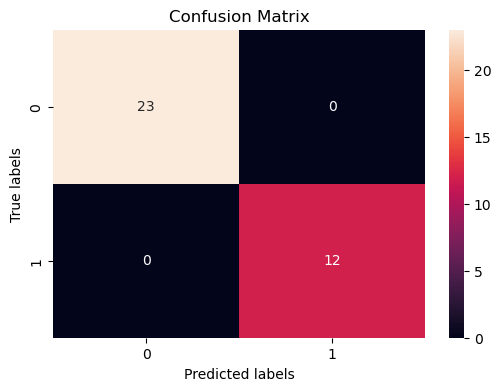

Classification Report:
              precision    recall  f1-score   support

           2       1.00      1.00      1.00        23
           4       1.00      1.00      1.00        12

    accuracy                           1.00        35
   macro avg       1.00      1.00      1.00        35
weighted avg       1.00      1.00      1.00        35



In [221]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf_RF.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

como se puede observar en el primer ejemplos la diagonal nos muestra que se realizaron 35 aciertos de 35 muestras clasifico correctamente las 23 benignas y 12 malignas. todo esto en solo 35 muestras de prueba  

## Random Forest - 15% Test Split

In [222]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15,  random_state = 5) # 85% training and 15% test

In [223]:
#Import Random Forest Model
from sklearn.ensemble import RandomForestClassifier

#Create a random forest Classifier
clf_RF = RandomForestClassifier(n_estimators = 100, random_state = 42)

#Train the model using the training sets y_pred=clf.predict(X_test)
clf_RF.fit(X_train, y_train)

y_pred = clf_RF.predict(X_test)

In [224]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 1.0
Accuracy: 1.00


In [225]:
# NEW SAMPLE prediction (correct way)
new_sample = [[1,2,3,4,5,6,7,8,9]]

prediction = clf_RF.predict(new_sample)              # predict class
proba = clf_RF.predict_proba(new_sample)             # predict probabilities

# Class names
print("Predicted Class:", prediction[0])

Predicted Class: 4


In [226]:
print("Confidence:", round(max(proba[0]), 3))

Confidence: 0.56


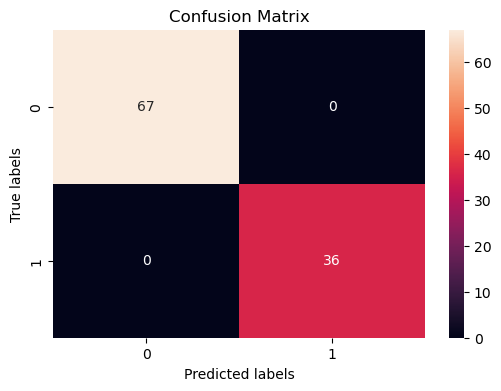

Classification Report:
              precision    recall  f1-score   support

           2       1.00      1.00      1.00        67
           4       1.00      1.00      1.00        36

    accuracy                           1.00       103
   macro avg       1.00      1.00      1.00       103
weighted avg       1.00      1.00      1.00       103



In [227]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf_RF.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

en la confusion matrix de 15% hemos conseguido un 100% en el conjunto mostrando 103 muestas 67 para benigna y 36 malignas sin errores

## Random Forest - 25% Test Split

In [228]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25,  random_state = 5) # 75% training and 25% test

In [229]:
#Import Random Forest Model
from sklearn.ensemble import RandomForestClassifier

#Create a random forest Classifier
clf_RF = RandomForestClassifier(n_estimators = 100, random_state = 42)

#Train the model using the training sets y_pred=clf.predict(X_test)
clf_RF.fit(X_train, y_train)

y_pred = clf_RF.predict(X_test)

In [230]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.9707602339181286
Accuracy: 0.97


In [231]:
# NEW SAMPLE prediction (correct way)
new_sample = [[1,2,3,4,5,6,7,8,9]]

prediction = clf_RF.predict(new_sample)              # predict class
proba = clf_RF.predict_proba(new_sample)             # predict probabilities

# Class names
print("Predicted Class:", prediction[0])

Predicted Class: 4


In [232]:
print("Confidence:", round(max(proba[0]), 3))

Confidence: 0.62


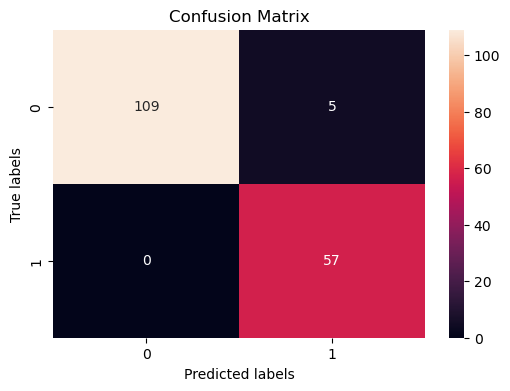

Classification Report:
              precision    recall  f1-score   support

           2       1.00      0.96      0.98       114
           4       0.92      1.00      0.96        57

    accuracy                           0.97       171
   macro avg       0.96      0.98      0.97       171
weighted avg       0.97      0.97      0.97       171



In [233]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf_RF.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

## logisticRegression 

In [234]:
df_new.head(10)

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2
5,8,10,10,8,7,10,9,7,1,4
6,1,1,1,1,2,10,3,1,1,2
7,2,1,2,1,2,1,3,1,1,2
8,2,1,1,1,2,1,1,1,5,2
9,4,2,1,1,2,1,2,1,1,2


In [235]:
df_new_means = df_new['Class'].mean()

df_new_means

2.6998535871156664

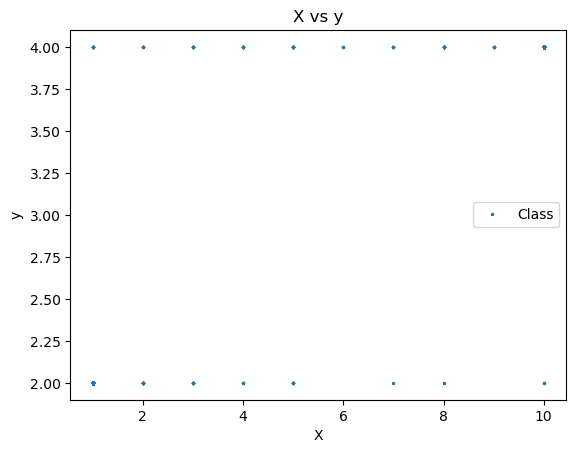

In [236]:
df_new.plot(x="Bare Nuclei", y='Class', style='*', markersize=2)
plt.title('X vs y')
plt.xlabel('X')
plt.ylabel('y')
plt.show()

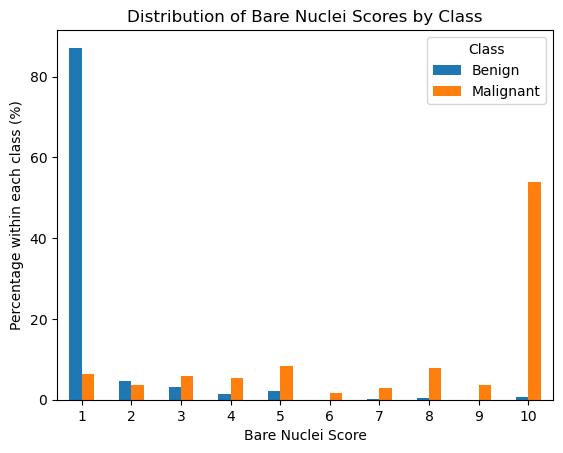

In [237]:
porcentajes = pd.crosstab(
    df_new["Bare Nuclei"],
    df_new["Class"],
    normalize="columns"
) * 100

porcentajes = porcentajes.rename(columns={2: "Benign", 4: "Malignant"})
porcentajes.plot(kind="bar", rot=0)

plt.title("Distribution of Bare Nuclei Scores by Class")
plt.xlabel("Bare Nuclei Score")
plt.ylabel("Percentage within each class (%)")
plt.show()

In [238]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=5
)

In [239]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_logistic):.2%}")

Test accuracy: 100.00%


In [178]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=5
)

In [179]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_logistic):.2%}")

Test accuracy: 99.03%


In [180]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=5
)

In [181]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_logistic):.2%}")

Test accuracy: 98.83%


In [182]:
from sklearn.linear_model import LogisticRegression
logistic_models = {"Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),}

In [184]:
# Reserve 0.5% for testing and use 95% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=5
)

results = []

for name, model in logistic_models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )
    results.append([name, scores.mean(), scores.std()])

results_5 = pd.DataFrame(
    results, columns=["Model", "Mean CV Accuracy", "CV Accuracy Std"]
)
results_5

,Model,Mean CV Accuracy,CV Accuracy Std
0,Logistic Regression,0.966023,0.019881


In [185]:
# Reserve 0.5% for testing and use 95% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=5
)

results = []

for name, model in logistic_models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )
    results.append([name, scores.mean(), scores.std()])

results_15 = pd.DataFrame(
    results, columns=["Model", "Mean CV Accuracy", "CV Accuracy Std"]
)
results_15

,Model,Mean CV Accuracy,CV Accuracy Std
0,Logistic Regression,0.963793,0.008447


In [186]:
# Reserve 0.5% for testing and use 95% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=5
)

results = []

for name, model in logistic_models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )
    results.append([name, scores.mean(), scores.std()])

results_25 = pd.DataFrame(
    results, columns=["Model", "Mean CV Accuracy", "CV Accuracy Std"]
)
results_25

,Model,Mean CV Accuracy,CV Accuracy Std
0,Logistic Regression,0.955054,0.027963


## validación cruzada de regresión

Validación cruzada de regresió 5%

In [187]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                 Model  Mean CV Accuracy
0        Random Forest          0.964921
1  Logistic Regression          0.966370


In [188]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),
}

In [193]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=5
)

In [194]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [195]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)   

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision  Recall  F1 Score
0        Random Forest       1.0        1.0     1.0       1.0
1  Logistic Regression       1.0        1.0     1.0       1.0


## Validación cruzada de regresió 15%

In [196]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),
}

In [200]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=5
)

In [201]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [202]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)   

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0        Random Forest  1.000000   1.000000  1.000000  1.000000
1  Logistic Regression  0.990291   0.990434  0.990291  0.990259


## Validación cruzada de regresió 25%

In [203]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),
}

In [204]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=5
)

In [205]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [206]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)   

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0        Random Forest  0.970760   0.973118  0.970760  0.971047
1  Logistic Regression  0.988304   0.988304  0.988304  0.988304


In [208]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}
    
    

In [210]:
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 0.5, 1, 10],
       
    },
    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 5 , 10, 20, 30],
       
    }
}

In [211]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2)
    grid_search.fit(X_train, y_train)
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_])

Running GridSearchCV for Logistic Regression...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


In [212]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_df)

Model Performance Metrics on Test Set after GridSearchCV:
                 Model  Accuracy  Precision    Recall  F1 Score  \
0  Logistic Regression  0.988304   0.988304  0.988304  0.988304   
1        Random Forest  0.970760   0.973118  0.970760  0.971047   

                        Best Parameters  
0                            {'C': 0.1}  
1  {'max_depth': 5, 'n_estimators': 50}  


In [213]:
# Cross-validation for accuracy on the full dataset using best models
cv_results = []
for name, classifier in classifiers.items():
    # Get the best model from GridSearchCV
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv=5, n_jobs=-1, verbose=2)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
    
    cv_scores = cross_val_score(best_model, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Fitting 5 folds for each of 15 candidates, totalling 75 fits


In [214]:
# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores after GridSearchCV:")
print(cv_results_df)


Cross-Validation Accuracy Scores after GridSearchCV:
                 Model  Mean CV Accuracy
0  Logistic Regression           0.96345
1        Random Forest           0.96784
